In [1]:

# Step 1 — Splitting the dataset into estimation and evaluation periods

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
dataset = pd.read_csv("Assignment1.csv")

# Select the 25 test portfolios
assets = [f"R{i}" for i in range(1, 26)]

# Convert asset returns into decimal excess returns
excess_returns = dataset[assets].sub(dataset["Rf"], axis=0) / 100

# Split into estimation and evaluation periods
estimation_returns = excess_returns.loc[dataset["Month"] <= 198712]
evaluation_returns = excess_returns.loc[dataset["Month"] >= 198801]

# Verify the sample sizes
print("Estimation observations:", len(estimation_returns))
print("Evaluation observations:", len(evaluation_returns))

Estimation observations: 456
Evaluation observations: 453


In [ ]:
# Step 2 — Estimating portfolio weights using the in-sample data

# Estimate expected excess returns and the covariance matrix
mean_excess_returns = estimation_returns.mean().to_numpy()
covariance_matrix = estimation_returns.cov().to_numpy()

# Calculate optimal portfolio weights
estimated_weights = np.linalg.solve(covariance_matrix, mean_excess_returns)

# Display the 25 portfolio weights
weights = pd.Series(estimated_weights, index=assets, name="Weight")

print(weights.round(4))
print("\nSum of weights:", round(weights.sum(), 4))

R1     -3.9519
R2     -2.7746
R3     -4.5503
R4      3.9127
R5      6.0450
R6     -4.7875
R7     -0.1359
R8      5.2564
R9      1.4268
R10     4.9846
R11    -0.3676
R12     4.8049
R13    -1.2501
R14     3.1685
R15    -2.4669
R16     3.1797
R17   -10.5346
R18     5.4716
R19     0.2948
R20    -1.8803
R21     0.9451
R22    -4.0587
R23     8.0408
R24    -4.0307
R25    -0.4787
Name: Weight, dtype: float64

Sum of weights: 6.263


In [4]:
# Step 3 — Calculating out-of-sample portfolio returns

# Apply the same estimated weights to both periods
portfolio_returns_estimation = estimation_returns @ estimated_weights
portfolio_returns_evaluation = evaluation_returns @ estimated_weights

# Compare portfolio performance across the two periods
for period, returns in {
    "Estimation": portfolio_returns_estimation,
    "Evaluation": portfolio_returns_evaluation
}.items():
    mean_return = returns.mean()
    volatility = returns.std(ddof=1)
    sharpe_ratio = mean_return / volatility

    print(f"{period} period:")
    print(f"  Mean excess return: {mean_return:.2%}")
    print(f"  Standard deviation: {volatility:.2%}")
    print(f"  Sharpe ratio: {sharpe_ratio:.4f}\n")

Estimation period:
  Mean excess return: 15.79%
  Standard deviation: 39.73%
  Sharpe ratio: 0.3973

Evaluation period:
  Mean excess return: 11.32%
  Standard deviation: 50.73%
  Sharpe ratio: 0.2232



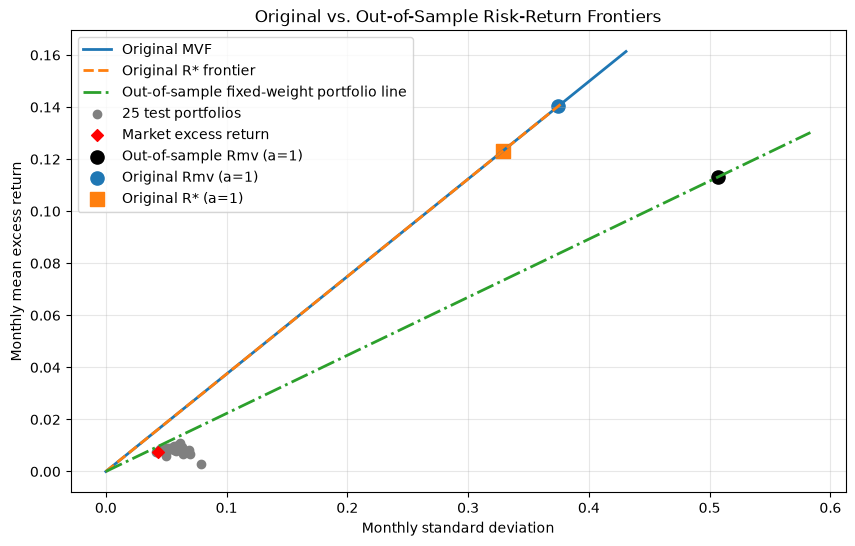

In [ ]:
# Step 4 — Comparing the original and out-of-sample frontiers (A)

# Reconstruct the original full-sample portfolios from Question 1
full_sample_means = excess_returns.mean().to_numpy()
full_sample_covariance = excess_returns.cov().to_numpy()

original_mv_weights = np.linalg.solve(full_sample_covariance, full_sample_means)
original_mv_returns = excess_returns @ original_mv_weights

# Alternative efficient portfolio (R*)
original_star_weights = np.linalg.lstsq(
    excess_returns.to_numpy(),
    np.ones(len(excess_returns)),
    rcond=None
)[0]
original_star_returns = excess_returns @ original_star_weights

# Generate the frontiers by scaling portfolio returns
scaling_factors = np.linspace(0, 1.15, 200)

plt.figure(figsize=(10, 6))

for returns, label, style in [
    (original_mv_returns, "Original MVF", "-"),
    (original_star_returns, "Original R* frontier", "--"),
    (portfolio_returns_evaluation, "Out-of-sample fixed-weight portfolio line", "-.")
]:
    plt.plot(
        scaling_factors * returns.std(ddof=1),
        scaling_factors * returns.mean(),
        style,
        label=label,
        linewidth=2
    )

# Plot the 25 assets using evaluation-period observations
plt.scatter(
    evaluation_returns.std(ddof=1),
    evaluation_returns.mean(),
    color="gray",
    label="25 test portfolios"
)

# Plot the evaluation-period market excess return
market_evaluation = (
    dataset.loc[dataset["Month"] >= 198801, "RM-Rf"] / 100
)

plt.scatter(
    market_evaluation.std(ddof=1),
    market_evaluation.mean(),
    color="red",
    marker="D",
    label="Market excess return"
)

# Mark the out-of-sample optimized portfolio
plt.scatter(
    portfolio_returns_evaluation.std(ddof=1),
    portfolio_returns_evaluation.mean(),
    color="black",
    s=90,
    label="Out-of-sample Rmv (a=1)"
)

plt.xlabel("Monthly standard deviation")
plt.ylabel("Monthly mean excess return")
plt.title("Original vs. Out-of-Sample Risk-Return Frontiers")

# Mark the original optimized portfolios (a = 1)
plt.scatter(
    original_mv_returns.std(ddof=1),
    original_mv_returns.mean(),
    marker="o", s=90, label="Original Rmv (a=1)"
)

plt.scatter(
    original_star_returns.std(ddof=1),
    original_star_returns.mean(),
    marker="s", s=90, label="Original R* (a=1)"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()


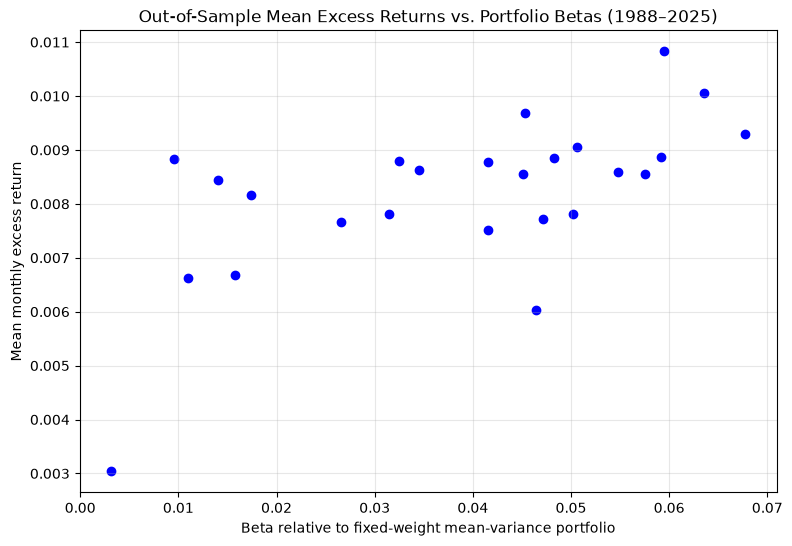

In [10]:
# Step 5 — Estimating out-of-sample betas and plotting mean excess returns (B)

# Prepare the regression variables
portfolio_return = portfolio_returns_evaluation.to_numpy()

# Include a constant to estimate the intercept (alpha)
X = np.column_stack([
    np.ones(len(portfolio_return)),
    portfolio_return
])

# Run 25 time-series OLS regressions
betas = []
alphas = []

for asset in assets:
    y = evaluation_returns[asset].to_numpy()

    alpha, beta = np.linalg.lstsq(X, y, rcond=None)[0]

    alphas.append(alpha)
    betas.append(beta)

# Collect regression results
beta_results = pd.DataFrame({
    "Asset": assets,
    "Beta": betas,
    "Mean excess return": evaluation_returns.mean().to_numpy(),
    "Alpha": alphas
})

# Plot betas against mean excess returns
plt.figure(figsize=(9, 6))

plt.scatter(beta_results["Beta"],beta_results["Mean excess return"],color="blue")

plt.xlabel("Beta relative to fixed-weight mean-variance portfolio")
plt.ylabel("Mean monthly excess return")
plt.title("Out-of-Sample Mean Excess Returns vs. Portfolio Betas (1988–2025)")
plt.grid(alpha=0.3)
plt.show()
